# Análise Exploratória de Dados (EDA) com Python
**Aula prática — Pandas, NumPy, Matplotlib e Seaborn**

## Objetivos
- Entender o que é EDA e por que ela é importante.
- Reconhecer tipos de variáveis.
- Inspecionar e resumir dados com Pandas e NumPy.
- Identificar ausências, duplicatas e inconsistências.
- Criar gráficos e interpretar padrões com cuidado.

> **Ideia central:** antes de tentar responder a uma pergunta com um modelo ou uma análise complexa, precisamos conhecer os dados.

## 1. O que é EDA?

A **Análise Exploratória de Dados (Exploratory Data Analysis — EDA)** é o processo de investigar um conjunto de dados para compreender sua estrutura, qualidade, padrões, distribuições e possíveis relações entre variáveis.

Perguntas comuns:
- Quantas linhas e colunas existem?
- O que cada coluna representa?
- Quais são os tipos de dados?
- Existem valores ausentes ou registros repetidos?
- Há valores fora do esperado?
- Como os dados estão distribuídos?

### Fluxo de trabalho
1. Conhecer o contexto e o significado das colunas.
2. Inspecionar dimensões, tipos e registros.
3. Resumir com estatísticas descritivas.
4. Limpar ausências, duplicatas e inconsistências.
5. Visualizar os dados.
6. Interpretar e registrar achados.

A EDA é iterativa: uma descoberta pode levar a novas perguntas.

## 2. Bibliotecas

| Biblioteca | Uso principal |
|---|---|
| **Pandas** | Organizar, selecionar, transformar e resumir tabelas |
| **NumPy** | Arrays e operações numéricas |
| **Matplotlib** | Construção e personalização de gráficos |
| **Seaborn** | Visualizações estatísticas |

Se necessário, instale as bibliotecas:

In [53]:
# Execute apenas se alguma biblioteca não estiver instalada:
# %pip install pandas numpy matplotlib seaborn

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.4.6


## 3. Tipos de variáveis

- **Numérica discreta:** contagens, como número de livros.
- **Numérica contínua:** medidas, como tempo ou temperatura.
- **Categórica nominal:** categorias sem ordem natural, como cidade.
- **Categórica ordinal:** categorias ordenáveis, como níveis de satisfação.
- **Temporal:** datas e horários.

Uma coluna armazenada como texto pode representar uma data que ainda precisa ser convertida.

## 4. Criando um conjunto de dados

Vamos usar dados fictícios de participantes de uma oficina. Eles são apenas didáticos e não representam pessoas reais.

In [55]:
dados = {
    "participante": ["Ana", "Bruno", "Caio", "Duda", "Elisa", "Fábio",
                     "Gabi", "Hugo", "Iara", "João", "Lia", "Maya"],
    "idade": [19, 22, 21, 24, 20, 23, 22, 25, 19, 21, 26, 20],
    "cidade": ["Recife", "Olinda", "Recife", "Paulista", "Olinda", "Recife",
               "Jaboatão", "Recife", "Olinda", "Paulista", "Recife", "Olinda"],
    "area": ["Dados", "Design", "Dados", "Pesquisa", "Design", "Dados",
             "Pesquisa", "Design", "Dados", "Pesquisa", "Design", "Dados"],
    "horas_estudo": [5.0, 3.5, 6.0, 4.0, np.nan, 7.0, 2.5, 5.5, 4.5, 3.0, 6.5, 5.0],
    "nota_projeto": [8.5, 7.0, 9.0, 8.0, 7.5, 9.5, 6.5, 8.0, 8.5, 7.0, 9.0, 8.0],
    "presencas": [9, 8, 10, 9, 7, 10, 6, 9, 8, 7, 10, 9],
    "data_inscricao": ["2026-03-02", "2026-03-03", "2026-03-03", "2026-03-04",
                       "2026-03-05", "2026-03-05", "2026-03-06", "2026-03-06",
                       "2026-03-07", "2026-03-07", "2026-03-08", "2026-03-08"]
}
df = pd.DataFrame(dados)
df

,participante,idade,cidade,area,horas_estudo,nota_projeto,presencas,data_inscricao
0,Ana,19,Recife,Dados,5.0,8.5,9,2026-03-02
1,Bruno,22,Olinda,Design,3.5,7.0,8,2026-03-03
2,Caio,21,Recife,Dados,6.0,9.0,10,2026-03-03
3,Duda,24,Paulista,Pesquisa,4.0,8.0,9,2026-03-04
4,Elisa,20,Olinda,Design,NaN,7.5,7,2026-03-05
5,Fábio,23,Recife,Dados,7.0,9.5,10,2026-03-05
6,Gabi,22,Jaboatão,Pesquisa,2.5,6.5,6,2026-03-06
7,Hugo,25,Recife,Design,5.5,8.0,9,2026-03-06
8,Iara,19,Olinda,Dados,4.5,8.5,8,2026-03-07
9,João,21,Paulista,Pesquisa,3.0,7.0,7,2026-03-07


## 5. Conhecendo a tabela com Pandas

Um `DataFrame` é uma estrutura tabular: cada linha representa um registro e cada coluna representa uma variável.

In [56]:
print("Dimensões:", df.shape)  # (linhas, colunas)
print("Colunas:", df.columns.tolist())
display(df.head())
display(df.tail(3))
df.info()

Dimensões: (12, 8)
Colunas: ['participante', 'idade', 'cidade', 'area', 'horas_estudo', 'nota_projeto', 'presencas', 'data_inscricao']


,participante,idade,cidade,area,horas_estudo,nota_projeto,presencas,data_inscricao
0,Ana,19,Recife,Dados,5.0,8.5,9,2026-03-02
1,Bruno,22,Olinda,Design,3.5,7.0,8,2026-03-03
2,Caio,21,Recife,Dados,6.0,9.0,10,2026-03-03
3,Duda,24,Paulista,Pesquisa,4.0,8.0,9,2026-03-04
4,Elisa,20,Olinda,Design,NaN,7.5,7,2026-03-05


,participante,idade,cidade,area,horas_estudo,nota_projeto,presencas,data_inscricao
9,João,21,Paulista,Pesquisa,3.0,7.0,7,2026-03-07
10,Lia,26,Recife,Design,6.5,9.0,10,2026-03-08
11,Maya,20,Olinda,Dados,5.0,8.0,9,2026-03-08


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participante    12 non-null     object 
 1   idade           12 non-null     int64  
 2   cidade          12 non-null     object 
 3   area            12 non-null     object 
 4   horas_estudo    11 non-null     float64
 5   nota_projeto    12 non-null     float64
 6   presencas       12 non-null     int64  
 7   data_inscricao  12 non-null     object 
dtypes: float64(2), int64(2), object(4)
memory usage: 900.0+ bytes


### Selecionando colunas e registros

- `df["coluna"]`: seleciona uma coluna.
- `df[["a", "b"]]`: seleciona várias colunas.
- `loc`: seleciona por rótulos e condições.
- `iloc`: seleciona por posições numéricas.

In [57]:
display(df["cidade"])
display(df[["area", "nota_projeto"]])
display(df.loc[df["nota_projeto"] >= 8, ["participante", "area", "nota_projeto"]])
display(df.iloc[:3, :2])

,cidade
0,Recife
1,Olinda
2,Recife
3,Paulista
4,Olinda
5,Recife
6,Jaboatão
7,Recife
8,Olinda
9,Paulista


,area,nota_projeto
0,Dados,8.5
1,Design,7.0
2,Dados,9.0
3,Pesquisa,8.0
4,Design,7.5
5,Dados,9.5
6,Pesquisa,6.5
7,Design,8.0
8,Dados,8.5
9,Pesquisa,7.0


,participante,area,nota_projeto
0,Ana,Dados,8.5
2,Caio,Dados,9.0
3,Duda,Pesquisa,8.0
5,Fábio,Dados,9.5
7,Hugo,Design,8.0
8,Iara,Dados,8.5
10,Lia,Design,9.0
11,Maya,Dados,8.0


,participante,idade
0,Ana,19
1,Bruno,22
2,Caio,21


## 6. Estatística descritiva

- **Média:** soma dos valores dividida pela quantidade.
- **Mediana:** valor central após ordenar os dados.
- **Mínimo e máximo:** extremos observados.
- **Desvio padrão:** medida de dispersão.
- **Quartis:** pontos que dividem os dados ordenados em quatro partes.

A média pode ser afetada por valores extremos; por isso, observe também mediana e quartis.

In [58]:
df.describe()

,idade,horas_estudo,nota_projeto,presencas
count,12.000000,11.000000,12.000000,12.000000
mean,21.833333,4.772727,8.041667,8.500000
std,2.289634,1.438117,0.915978,1.314257
min,19.000000,2.500000,6.500000,6.000000
25%,20.000000,3.750000,7.375000,7.750000
50%,21.500000,5.000000,8.000000,9.000000
75%,23.250000,5.750000,8.625000,9.250000
max,26.000000,7.000000,9.500000,10.000000


In [59]:
coluna = df["horas_estudo"]
print("Média:", coluna.mean())
print("Mediana:", coluna.median())
print("Mínimo:", coluna.min())
print("Máximo:", coluna.max())
print("Desvio padrão:", coluna.std())

print("\nFrequência por área:")
display(df["area"].value_counts())
display(df["area"].value_counts(normalize=True).round(2))

Média: 4.7727272727272725
Mediana: 5.0
Mínimo: 2.5
Máximo: 7.0
Desvio padrão: 1.4381174563233068

Frequência por área:


,count
area,
Dados,5
Design,4
Pesquisa,3


,proportion
area,
Dados,0.42
Design,0.33
Pesquisa,0.25


## 7. Qualidade dos dados

Dados reais podem conter ausências, duplicatas e inconsistências. Antes de tratar qualquer valor, investigue o que ele significa. Um valor ausente não deve ser preenchido automaticamente sem considerar o contexto.

In [60]:
# Quantidade de valores ausentes por coluna
display(df.isna().sum())

# Percentual de ausências por coluna
display((df.isna().mean() * 100).round(1))

# Quantidade de linhas duplicadas
print("Linhas duplicadas:", df.duplicated().sum())

,0
participante,0
idade,0
cidade,0
area,0
horas_estudo,1
nota_projeto,0
presencas,0
data_inscricao,0


,0
participante,0.0
idade,0.0
cidade,0.0
area,0.0
horas_estudo,8.3
nota_projeto,0.0
presencas,0.0
data_inscricao,0.0


Linhas duplicadas: 0


### Tratando valores ausentes

Estratégias possíveis:
- manter o valor ausente;
- remover registros ou colunas, se justificável;
- preencher com uma estatística, como mediana;
- buscar a informação na fonte original.

A célula seguinte é apenas uma demonstração: em um projeto real, justifique a estratégia escolhida.

In [61]:
df_tratado = df.copy()
mediana_horas = df_tratado["horas_estudo"].median()
df_tratado["horas_estudo"] = df_tratado["horas_estudo"].fillna(mediana_horas)

print("Mediana usada:", mediana_horas)
display(df_tratado.isna().sum())

Mediana usada: 5.0


,0
participante,0
idade,0
cidade,0
area,0
horas_estudo,0
nota_projeto,0
presencas,0
data_inscricao,0


### Convertendo datas

Datas armazenadas como texto podem ser convertidas para o tipo temporal com `pd.to_datetime`.

In [62]:
df_tratado["data_inscricao"] = pd.to_datetime(df_tratado["data_inscricao"])
print(df_tratado.dtypes)
display(df_tratado[["participante", "data_inscricao"]].head())

participante              object
idade                      int64
cidade                    object
area                      object
horas_estudo             float64
nota_projeto             float64
presencas                  int64
data_inscricao    datetime64[ns]
dtype: object


,participante,data_inscricao
0,Ana,2026-03-02
1,Bruno,2026-03-03
2,Caio,2026-03-03
3,Duda,2026-03-04
4,Elisa,2026-03-05


## 8. Visualização de dados

O gráfico deve ser escolhido de acordo com a pergunta:
- barras: comparar categorias;
- histograma: observar distribuição numérica;
- boxplot: comparar distribuição e dispersão;
- dispersão: explorar relação entre duas variáveis;
- mapa de calor: visualizar uma matriz de correlação.

### 8.1 Barras — comparar categorias

Pergunta: quantas pessoas estão em cada área?

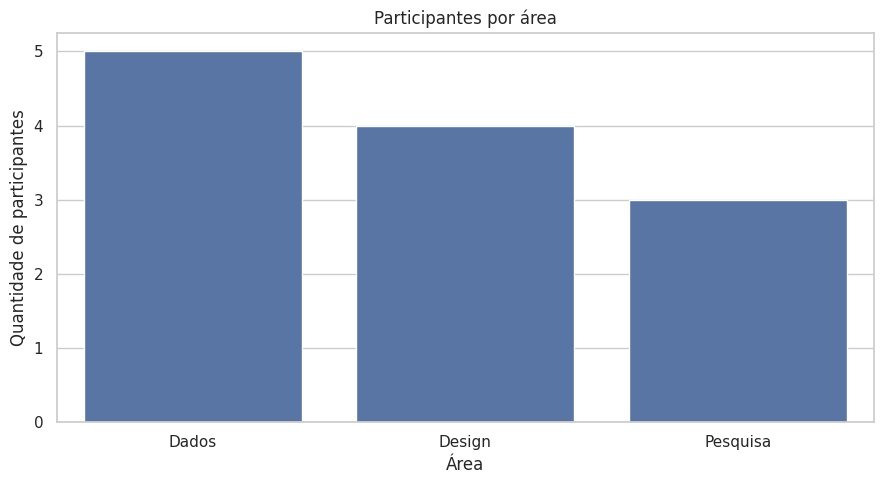

In [63]:
ordem = df["area"].value_counts().index
sns.countplot(data=df, x="area", order=ordem)
plt.title("Participantes por área")
plt.xlabel("Área")
plt.ylabel("Quantidade de participantes")
plt.tight_layout()
plt.show()

### 8.2 Histograma — observar distribuição

Pergunta: como estão distribuídas as notas dos projetos?

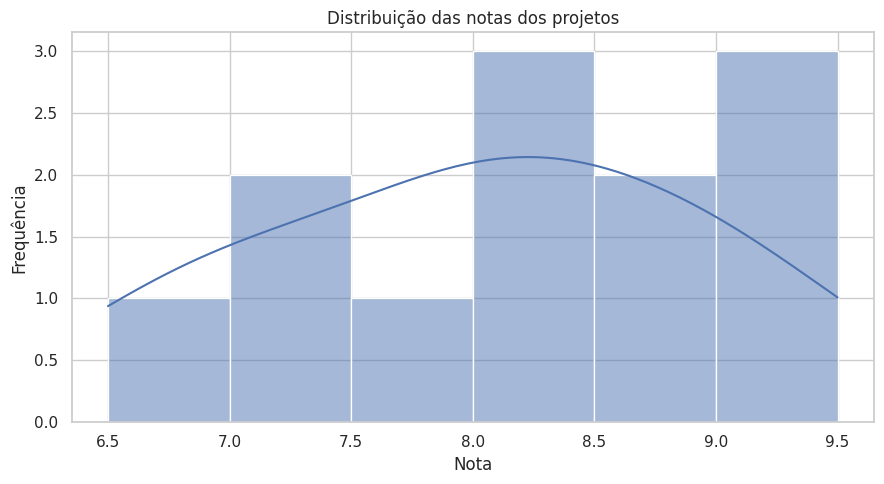

In [64]:
sns.histplot(data=df, x="nota_projeto", bins=6, kde=True)
plt.title("Distribuição das notas dos projetos")
plt.xlabel("Nota")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

### 8.3 Boxplot — comparar distribuição

O boxplot resume mediana, quartis e possíveis pontos extremos. Um ponto extremo precisa ser investigado; não é necessariamente um erro.

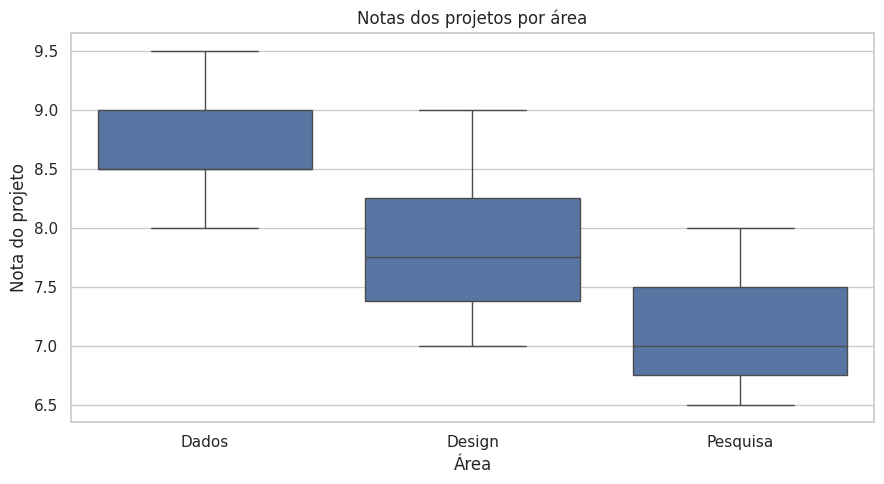

In [65]:
sns.boxplot(data=df, x="area", y="nota_projeto")
plt.title("Notas dos projetos por área")
plt.xlabel("Área")
plt.ylabel("Nota do projeto")
plt.tight_layout()
plt.show()

### 8.4 Dispersão — observar relação entre variáveis

Pergunta: neste conjunto, horas de estudo parecem acompanhar notas maiores?

Uma associação visual não prova que uma variável causa a outra.

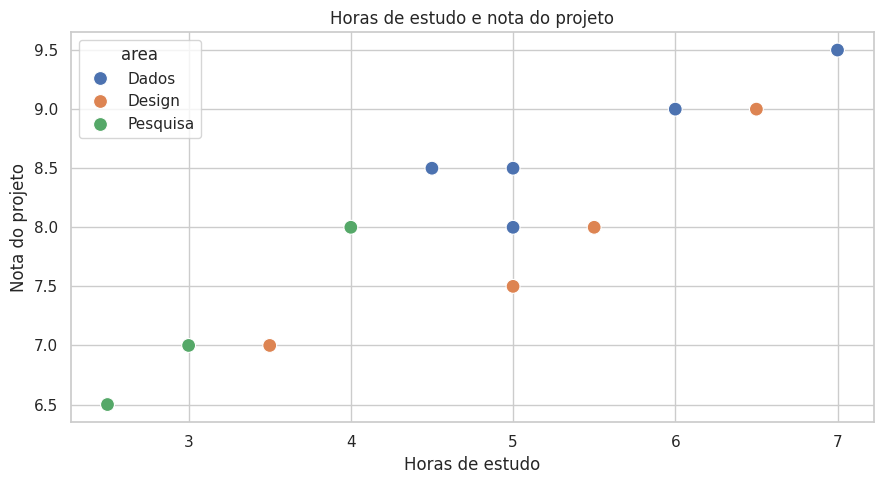

In [66]:
sns.scatterplot(data=df_tratado, x="horas_estudo", y="nota_projeto",
                hue="area", s=100)
plt.title("Horas de estudo e nota do projeto")
plt.xlabel("Horas de estudo")
plt.ylabel("Nota do projeto")
plt.tight_layout()
plt.show()

### 8.5 Correlação

A correlação mede a intensidade e a direção de uma relação linear. Valores próximos de `1` indicam associação positiva; próximos de `-1`, negativa; próximos de `0`, pouca associação linear.

**Correlação não implica causalidade.** Ela também pode ser influenciada por valores extremos e por outras variáveis.

,idade,horas_estudo,nota_projeto,presencas
idade,1.00,0.28,0.16,0.36
horas_estudo,0.28,1.00,0.91,0.84
nota_projeto,0.16,0.91,1.00,0.89
presencas,0.36,0.84,0.89,1.00


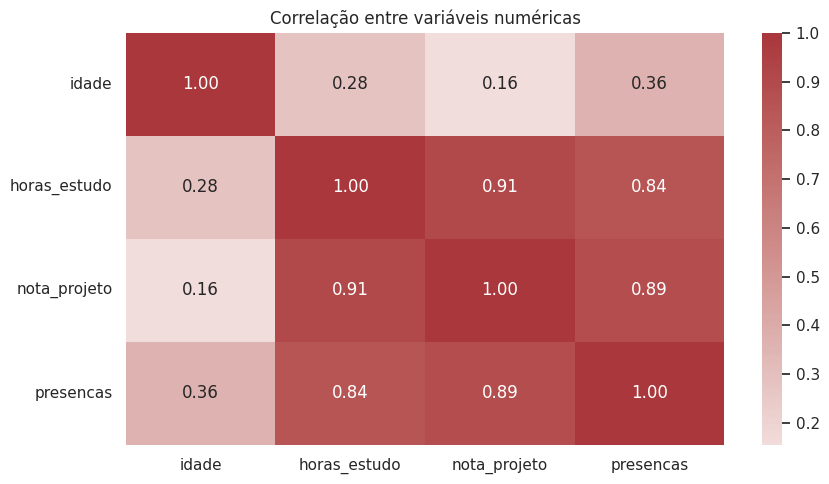

In [67]:
numericas = df_tratado.select_dtypes(include="number")
correlacao = numericas.corr()
display(correlacao.round(2))

sns.heatmap(correlacao, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

## 9. Agrupamento com Pandas

`groupby` permite resumir dados por categoria. Aqui calculamos quantidade de participantes, nota média e horas médias por área.

In [68]:
resumo_area = (
    df_tratado.groupby("area")
    .agg(
        participantes=("participante", "count"),
        nota_media=("nota_projeto", "mean"),
        horas_medias=("horas_estudo", "mean")
    )
    .round(2)
    .sort_values("nota_media", ascending=False)
)
display(resumo_area)

,participantes,nota_media,horas_medias
area,,,
Dados,5,8.70,5.50
Design,4,7.88,5.12
Pesquisa,3,7.17,3.17


## 10. NumPy: operações numéricas

O NumPy oferece arrays e operações vetorizadas, permitindo realizar cálculos sobre vários valores de uma vez.

In [69]:
notas = np.array(df["nota_projeto"])
print("Array:", notas)
print("Média:", np.mean(notas))
print("Mediana:", np.median(notas))
print("Desvio padrão:", np.std(notas))
print("Notas acima de 8:", notas[notas > 8])

# Exemplo: converter escala de 0–10 para 0–100
print("Escala percentual:", notas * 10)

Array: [8.5 7.  9.  8.  7.5 9.5 6.5 8.  8.5 7.  9.  8. ]
Média: 8.041666666666666
Mediana: 8.0
Desvio padrão: 0.8769818824937162
Notas acima de 8: [8.5 9.  9.5 8.5 9. ]
Escala percentual: [85. 70. 90. 80. 75. 95. 65. 80. 85. 70. 90. 80.]


## 11. Como registrar os achados

Uma boa análise não termina no gráfico. Registre:
1. **Pergunta:** o que você queria descobrir?
2. **Evidência:** qual tabela, estatística ou gráfico observou?
3. **Interpretação:** o que os dados sugerem?
4. **Limitação:** o que não é possível concluir?
5. **Próximo passo:** que informação ajudaria?

Exemplo: “Neste pequeno conjunto fictício, o gráfico permite explorar uma possível associação entre horas de estudo e nota. Porém, a quantidade de registros é pequena e não permite concluir que estudar mais causa notas maiores.”

## 12. Exercícios

Tente resolver antes de consultar as sugestões de código.

1. **Inspeção:** quantas linhas e colunas existem? Quais colunas são numéricas? Qual coluna contém ausência?
2. **Frequências:** qual cidade aparece mais vezes? Quantos participantes são da área de Dados?
3. **Estatística:** calcule média e mediana das notas. São iguais?
4. **Visualização:** faça um gráfico de barras por cidade e um histograma de horas de estudo.
5. **Investigação:** compare a nota média por área. Escreva uma observação e uma limitação.

In [70]:
# Exercício 1
print("Dimensões:", df.shape)
display(df.dtypes)
display(df.isna().sum())

Dimensões: (12, 8)


,0
participante,object
idade,int64
cidade,object
area,object
horas_estudo,float64
nota_projeto,float64
presencas,int64
data_inscricao,object


,0
participante,0
idade,0
cidade,0
area,0
horas_estudo,1
nota_projeto,0
presencas,0
data_inscricao,0


**Resposta exercício 1:**

Existem 12 linhas e 8 colunas (código: df.shape)

Colunas numéricas: Idade, horas_estudo, nota_projeto e presencas (codigo: display(df.dtypes))

A coluna horas_estudo contém 1 ausência (código: display(df.isna().sum()))

In [71]:
# Exercício 2
display(df["cidade"].value_counts())
display(df["area"].value_counts())

,count
cidade,
Recife,5
Olinda,4
Paulista,2
Jaboatão,1


,count
area,
Dados,5
Design,4
Pesquisa,3


**Resposta exercício 2:**

A cidade de Recife aparece mais vezes. (Comando: display(df["cidade"].value_counts()))

5 participantes são da área de dados. (Comando: display(df["area"].value_counts()))

In [72]:
# Exercício 3
print("Média:", df["nota_projeto"].mean())
print("Mediana:", df["nota_projeto"].median())

Média: 8.041666666666666
Mediana: 8.0


**Resposta exercício 3:**

Média das notas é aproximadamente 8.041. (Comando: print("Média:", df["nota_projeto"].mean()))

A mediana é 8.0. (Comando: print("Mediana:", df["nota_projeto"].median()))

Elas não são iguais, mas são muito proximas, 8.041 != 8.0.

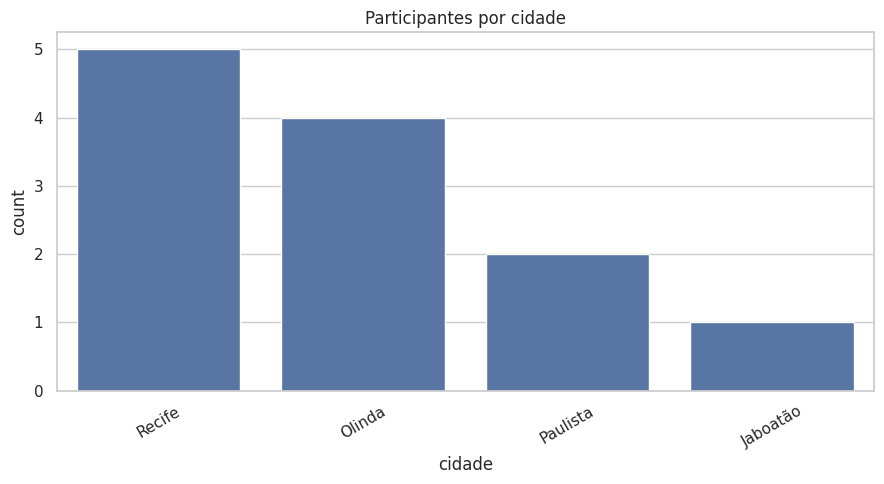

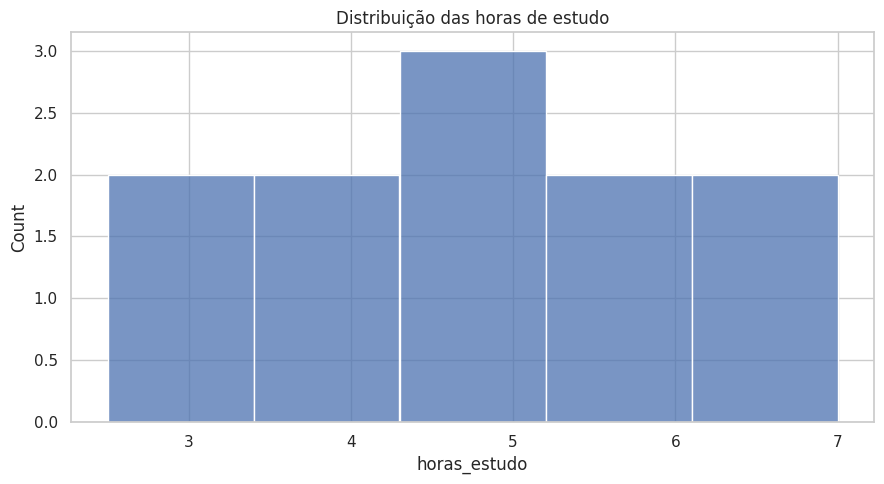

In [73]:
# Exercício 4 — gráfico por cidade
sns.countplot(data=df, x="cidade")
plt.xticks(rotation=30)
plt.title("Participantes por cidade")
plt.tight_layout()
plt.show()

# Histograma de horas de estudo
sns.histplot(data=df, x="horas_estudo", bins=5)
plt.title("Distribuição das horas de estudo")
plt.tight_layout()
plt.show()

In [74]:
# Exercício 5
display(df.groupby("area")["nota_projeto"].mean().sort_values(ascending=False))

,nota_projeto
area,
Dados,8.700000
Design,7.875000
Pesquisa,7.166667


**Comparação:** A área de Dados possui a maior nota média (8,70), seguida por Design (7,88) e Pesquisa (7,17).

**Observação:** A área de Dados apresenta a maior média dentre as três e tem uma diferença de 1,53 ponto em relação à menor média (Pesquisa).

**Limitação:** O conjunto de dados possui apenas 12 registros no total, o que é uma amostra muito pequena. Além disso, a média é sensível a outliers, então não dá para afirmar que a área de Dados é superior de forma generalizada, nem se a média foi puxada por uma única nota muito alta ou muito baixa em algum grupo.

## 13. Referência rápida

| Objetivo | Comando |
|---|---|
| Primeiras linhas | `df.head()` |
| Dimensões | `df.shape` |
| Tipos e ausências | `df.info()` |
| Estatísticas | `df.describe()` |
| Frequência de categorias | `df["coluna"].value_counts()` |
| Ausências | `df.isna().sum()` |
| Duplicatas | `df.duplicated().sum()` |
| Filtrar | `df.loc[condicao]` |
| Agrupar | `df.groupby("coluna").agg(...)` |
| Correlação | `df.corr(numeric_only=True)` |
| Histograma | `sns.histplot(...)` |
| Barras | `sns.countplot(...)` |
| Dispersão | `sns.scatterplot(...)` |
| Boxplot | `sns.boxplot(...)` |

## Encerramento

EDA é uma prática de curiosidade disciplinada: observar, questionar, verificar e comunicar. O objetivo não é produzir o maior número de gráficos, mas construir uma compreensão confiável dos dados e descobrir quais perguntas devem vir em seguida.

**Próximo passo:** escolha um conjunto de dados de seu interesse e repita o fluxo desta aula, registrando suas decisões e justificativas.

# Exercício final para casa — Explorando a base Iris

**Objetivo:** aplicar o fluxo de Análise Exploratória de Dados (EDA) a uma base clássica de aprendizagem de máquina: o conjunto **Iris**, disponível no scikit-learn.

A base contém medidas de flores de três espécies: *setosa*, *versicolor* e *virginica*. Cada registro representa uma flor; as variáveis incluem comprimento e largura das sépalas e das pétalas.

## Carregando a base

Execute a célula abaixo. Esta é a única célula de código fornecida para iniciar a atividade. Faça as análises e construa as visualizações necessárias por conta própria, usando os recursos estudados em aula.

In [75]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df_iris = iris.frame
df_iris["species"] = df_iris["target"].map(dict(enumerate(iris.target_names)))
df_iris = df_iris.drop(columns="target")

df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## As três perguntas da investigação

Responda usando tabelas, estatísticas e visualizações adequadas. Não basta apresentar um gráfico: escreva uma interpretação em suas próprias palavras e explique o que os dados permitem — ou não permitem — concluir.

### 1. Como as três espécies estão representadas na base?

Investigue a quantidade de flores de cada espécie.

Na resposta:
- informe quantas observações existem para cada espécie;
- compare as quantidades;
- apresente uma visualização que ajude a comparar as espécies.

### 2. Quais características das pétalas melhor diferenciam as espécies?

Compare o comprimento e a largura das pétalas entre *setosa*, *versicolor* e *virginica*.

Na resposta:
- apresente medidas-resumo que permitam comparar as espécies;
- use pelo menos uma visualização adequada;
- indique qual característica parece separar melhor as espécies e justifique sua interpretação com evidências da base.

### 3. Existe uma relação entre o comprimento da sépala e o comprimento da pétala?

Investigue a relação entre essas duas medidas considerando o conjunto completo e observando também as espécies.

Na resposta:
- apresente um gráfico adequado para observar a relação;
- descreva o padrão encontrado;
- explique se a relação parece igual nas três espécies;
- lembre-se: uma associação observada não prova que uma característica cause a outra.

## Entrega

Organize as respostas no próprio notebook, abaixo de cada pergunta, incluindo:
- código usado na análise;
- tabelas ou estatísticas relevantes;
- gráficos com título e nomes dos eixos;
- uma interpretação escrita para cada pergunta.

**Conclusão final:** escreva um pequeno parágrafo resumindo o que descobriu sobre a base Iris e cite uma limitação da sua análise.

**Critério principal:** valorize a qualidade da investigação e da interpretação, não a quantidade de gráficos. Explique como cada resultado ajuda a responder à pergunta.

**Respostas**:


**Pergunta 1:**

Iremos analisar o dataset, ver a distruição de linhas e colunas, tipos de variáveis, valores nulos, checar a quantidade de flores de cada espécie e plotar um gráfico para comparar as espécies:


(150, 5)

,0
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
species,object


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


np.int64(1)

,count
species,
setosa,50
versicolor,50
virginica,50


<function matplotlib.pyplot.show(close=None, block=None)>

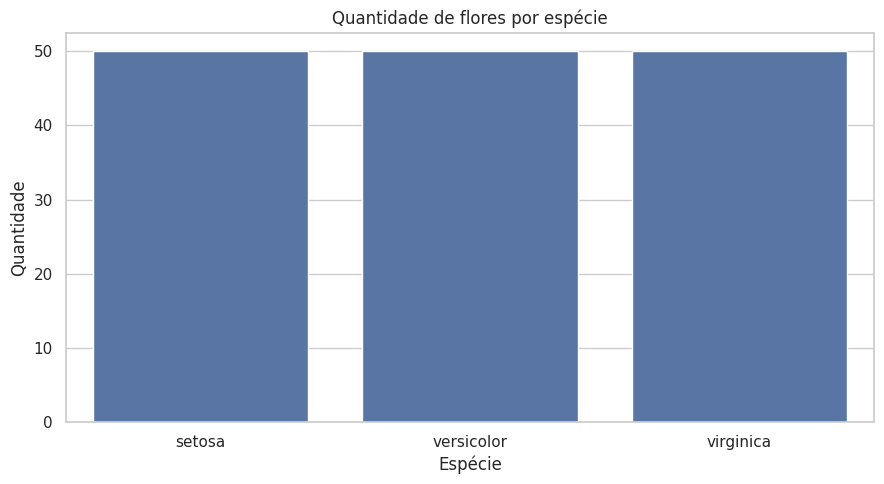

In [76]:
display(df_iris.shape)
display(df_iris.dtypes)
display(df_iris.isna().sum())
display(df_iris.duplicated().sum())
display(df_iris["species"].value_counts())

sns.countplot(data=df_iris, x="species")
plt.title("Quantidade de flores por espécie")
plt.xlabel("Espécie")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()

**Quantidade de observações:** Existem 50 observações para cada uma das três espécies (setosa, versicolor e virginica), no total, 150 registros.   
**Comparação:** Todas as espécies possuem exatamente a mesma quantidade de registros, o que indica que a base de dados está perfeitamente balanceada entre as classes.   

**Pergunta 2:**

Para responder essa, precisamos apresentar medidas que possam comparar as espécies. Portanto, compararemos a largura e comprimento das pétalas com o .describe() e iremos plotar um gráfico que seja possível visualizar a comparação:

petal length (cm)                                               \
                       count   mean       std  min  25%   50%    75%  max   
species                                                                     
setosa                  50.0  1.462  0.173664  1.0  1.4  1.50  1.575  1.9   
versicolor              50.0  4.260  0.469911  3.0  4.0  4.35  4.600  5.1   
virginica               50.0  5.552  0.551895  4.5  5.1  5.55  5.875  6.9   

           petal width (cm)                                            
                      count   mean       std  min  25%  50%  75%  max  
species                                                                
setosa                 50.0  0.246  0.105386  0.1  0.2  0.2  0.3  0.6  
versicolor             50.0  1.326  0.197753  1.0  1.2  1.3  1.5  1.8  
virginica              50.0  2.026  0.274650  1.4  1.8  2.0  2.3  2.5

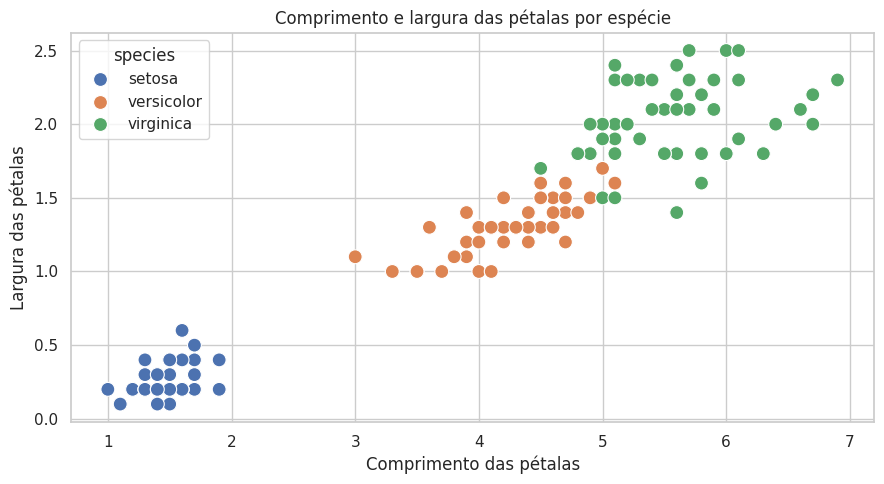

In [86]:
display(df_iris.groupby("species")[["petal length (cm)", "petal width (cm)"]].describe())
sns.scatterplot(data=df_iris, x="petal length (cm)", y="petal width (cm)", hue="species", s=100)
plt.title("Comprimento e largura das pétalas por espécie")
plt.xlabel("Comprimento das pétalas")
plt.ylabel("Largura das pétalas")
plt.tight_layout()
plt.show()


**Comparação e evidências:** Analisando a tabela e o scatterplot, a setosa apresenta as menores pétalas, ficando totalmente isolada das outras duas espécies. A versicolor fica no meio termo entre as duas, enquanto a virginica possui as maiores pétalas.   
**Característica que melhor separa:** Embora qualquer uma das duas características consiga separar perfeitamente a setosa, o comprimento da pétala separa melhor a versicolor e a virginica, pois a grande maioria das observações de cada espécie ocupa faixas distintas (75% das *versicolor* vão até 4,60 cm, enquanto 75% das *virginica* estão acima de 5,10 cm), havendo pouca sobreposição.

**Pergunta 3:**

Correlação geral: 0.8717537758865831


sepal length (cm)  petal length (cm)
species                                                           
setosa     sepal length (cm)           1.000000           0.267176
           petal length (cm)           0.267176           1.000000
versicolor sepal length (cm)           1.000000           0.754049
           petal length (cm)           0.754049           1.000000
virginica  sepal length (cm)           1.000000           0.864225
           petal length (cm)           0.864225           1.000000

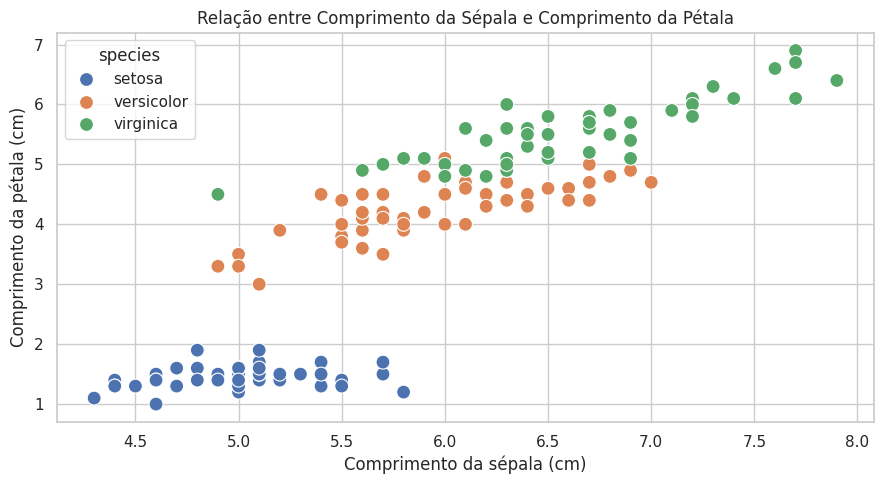

In [91]:
print("Correlação geral:", df_iris["sepal length (cm)"].corr(df_iris["petal length (cm)"]))
display(df_iris.groupby("species")[["sepal length (cm)", "petal length (cm)"]].corr())

sns.scatterplot(data=df_iris, x="sepal length (cm)", y="petal length (cm)", hue="species", s=100)
plt.title("Relação entre Comprimento da Sépala e Comprimento da Pétala")
plt.xlabel("Comprimento da sépala (cm)")
plt.ylabel("Comprimento da pétala (cm)")
plt.tight_layout()
plt.show()

Analisando o dataset, podemos dizer que o comprimento da sépala e o comprimento da pétala possuem correlação alta, 0.87 aproximadamente.

Porém, é possível notar que na setosa o comprimento da pétala não aumenta mesmo quando o comprimento da sépala aumenta, logo, eles não possuem correlação forte. Já na versicolor e na virginica, dá pra ver pelo scatterplot que elas formam uma diagonal crescente, ou seja, quanto maior o comprimento da sépala, maior tende a ser o comprimento da pétala, havendo também algumas anomalias.

Isso tudo só mostra que apesar da forte associação observada nos dados, isso não significa que o crescimento da sépala cause diretamente o crescimento da pétala.